# Fast Imaging Pulse Sequences

**Part:** H – Imaging methods · **Reading time:** ~75 min · **Pass 1 overview:** [Speed, Artifacts and Safety](../pass1_big_picture/P1.5_Speed_Artifacts_and_Safety.ipynb) · **Refreshers you may want:** [Fourier properties (shift theorem)](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb), [ODEs (steady states of linear recurrences)](../refreshers/RM1_ODEs_for_MRI.ipynb)

Modern MRI scanning relies heavily on **fast imaging pulse sequences**, primarily **echo-planar imaging (EPI)** and **multiple spin-echo** (RARE/FSE/TSE) methods, which acquire *many* k-space lines within a single TR, and on **fast gradient-echo** sequences, which make TR itself very short. A basic spin echo needs one TR per k-space line, so $T_{scan}=TR\cdot N_{PE}\cdot NEX$; for T2 weighting (TR ≈ 4 s) that is 17 minutes for 256 lines. The sequences in this chapter bring that down to a minute or less. Each comes with its own physics: specific contrasts, artifacts (blurring, distortion, ghosts, banding), and hardware limits (SAR, gradient slew rate). Knowing these is essential to read and set up any clinical protocol.

## Learning goals

1. Describe how images are formed
    * Describe how data is acquired in FSE/TSE sequences (echo train, k-space ordering)
    * Describe how EPI works (k-space trajectory, blips, echo spacing)
    * Understand what "spoiling" means (gradient and RF spoiling)
1. Understand the most popular pulse sequences and their acronyms
    * Describe how FSE/TSE sequences work
    * Describe how EPI works
    * Describe how fast gradient-echo sequences work (spoiled GRE, SSFP-FID, SSFP-echo, bSSFP) and magnetization-prepared sequences (MPRAGE)
    * Translate vendor acronyms (Siemens, GE, Philips, Canon)
1. Manipulate MRI sequence parameters to improve performance
    * Understand how and when to accelerate with FSE/TSE (ETL, $TE_{eff}$)
    * Understand how and when to accelerate with EPI (echo spacing, segmentation)
    * Understand how contrast changes in fast gradient-echo sequences (flip angle, TR, spoiling)
1. Identify artifacts and how to mitigate them
    * Identify FSE/TSE artifacts including T2 blurring
    * Identify EPI artifacts including distortion, chemical shift, N/2 ghosting and T2* blurring
    * Identify fast gradient-echo artifacts such as banding in bSSFP
1. Manipulate and analyze MRI data
    * Simulate echo trains, EPI distortion and ghosts, spoiling, bSSFP off-resonance profiles and MPRAGE signal evolution in Python

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $TR$, $TE$, $TI$ | repetition, echo, inversion time | s | |
| $t_{esp}$ | echo spacing: time between successive echoes (FSE) or gradient echoes/readouts (EPI) | s | FSE 5–15 ms, EPI 0.3–1 ms |
| $ETL$ | echo train length: echoes (= k-space lines) acquired per excitation | – | FSE 4–256, EPI 32–256 |
| $TE_{eff}$ | effective echo time: time at which the centre of k-space ($k_y = 0$) is acquired | s | |
| $N_{shots}$ | number of excitations needed: $N_{PE}/ETL$ | – | 1 = "single-shot" |
| $N_{PE}$, $N_x$ | phase-encode lines, readout samples | – | 64–512 |
| $NEX$ | number of averages | – | |
| $T_{scan}$ | scan time | s | |
| $T_1$, $T_2$, $T_2^*$ | relaxation time constants | s | WM ≈ 0.6 s / 80 ms at 1.5 T |
| $E_1=e^{-TR/T_1}$, $E_2=e^{-TR/T_2}$ | relaxation factors over one TR | – | |
| $\theta$ | flip angle | rad (°) | GRE 5–70°, bSSFP 30–70° |
| $\theta_E$ | Ernst angle (maximizes spoiled-GRE signal) | rad | $\arccos E_1$ |
| $\varphi_n$ | phase (axis direction in the xy-plane) of RF pulse $n$ | rad | RF spoiling: quadratic in $n$ |
| $\beta$ | precession angle accumulated during one TR by off-resonance | rad | $2\pi\Delta f\,TR$ |
| $\Delta f$ | off-resonance frequency (field inhomogeneity + chemical shift) | Hz | 10–500 Hz |
| $\Delta f_{cs}$ | chemical shift of fat vs water | Hz | −3.5 ppm: −220 Hz @1.5 T, −440 Hz @3 T |
| $\Delta t$, $BW_{read}$ | dwell time; readout bandwidth $1/\Delta t$ | s, Hz | 4 µs, 250 kHz |
| $BW_{pix,read}$, $BW_{pix,PE}$ | bandwidth per pixel in readout / phase-encode direction | Hz/pixel | EPI: ~2 kHz vs ~20–40 Hz |
| $k_x$, $k_y$ | k-space coordinates | m⁻¹ | |
| $G_x$, $G_y$ | readout and phase-encode (blip) gradients | T/m | up to 40–80 mT/m |
| $SR$ | slew rate (max $dG/dt$) | T/m/s | 100–200 |
| $FOV$, $\delta_y$ | field of view; pixel size ($FOV/N$) | m | 0.24 m, 2–3 mm (EPI) |
| $\Delta y$ | displacement of a pixel's signal along the PE direction | m (or pixels) | |
| $\phi$ | odd/even echo phase mismatch in EPI | rad | |
| $w(k_y)$ | k-space modulation: relative signal weight of each PE line | – | e.g. $e^{-t(k_y)/T_2}$ |
| $h(y)$ | point spread function (PSF) along PE, $=\mathcal F^{-1}\{w\}$ | – | |
| $M_z$, $M_{xy}$ | longitudinal / transverse magnetization ($M_0=1$) | – | rotating frame |
| $m(\vec r)$, $M(\vec k)$ | image; k-space data (**not** the magnetization $\vec M$) | a.u. | |
| $T_{D}$, $N_{seg}$ | MPRAGE: delay after the readout train; number of GRE readouts per preparation | s, – | 0.5–1 s, 100–200 |
| $TR_{prep}$ | MPRAGE: time between inversions ("TR" on the scanner console) | s | 2–2.5 s |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 0. Three routes to speed

$$T_{scan} = TR \cdot N_{TR} \cdot NEX, \qquad N_{TR} = \frac{N_{PE}}{\text{lines per TR}}.$$

In words: scan time is the repetition time × how many repetitions are needed × averages; the number of repetitions is the number of phase-encode lines divided by how many lines we acquire per repetition.

So there are three routes:

1. **More lines per TR**: echo trains (FSE/TSE: many spin echoes; EPI: many gradient echoes). Sections 1–2.
2. **Shorter TR**: fast gradient-echo sequences with TR of a few ms. Contrast then comes from steady-state behaviour or from magnetization preparation. Sections 3–4.
3. **Fewer lines**: undersampling with partial Fourier, parallel imaging, compressed sensing, deep learning. See [Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb).

## 1. Multiple spin-echo sequences (RARE / FSE / TSE)

These sequences use multiple spin-echo refocusing pulses after a single excitation pulse, so multiple k-space lines can be acquired during the multiple spin echoes that form. The technique was originally called **Rapid Acquisition with Relaxation Enhancement (RARE)** (Hennig 1986). It is known as **fast spin echo (FSE)** at GE HealthCare and **turbo spin echo (TSE)** at Siemens Healthineers and Philips Healthcare (Canon: "FSE"). *(The original text listed Philips' name as "turbo field echo (TFE)"; that is wrong. TFE is Philips' name for a fast, typically magnetization-prepared, **gradient**-echo sequence; Philips also uses "TSE".)*

This is **the most commonly used pulse sequence in clinical practice**. It is highly SNR-efficient and can produce multiple contrasts; it is particularly effective for T2- and PD-weighted imaging.

### 1.1 Simplified pulse sequence diagram

![Multiple spin-echo pulse sequence: one 90° pulse followed by a train of 180° refocusing pulses; each echo between two 180° pulses gets its own phase-encode step (and is rewound afterwards).](../images/pulse_sequence-diagram-fastspinecho-simple.png)

How it works, step by step (recall spin echoes from [Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)):

1. A 90° pulse tips $M_z$ into the transverse plane at $t=0$.
2. 180° refocusing pulses follow at $t_{esp}/2,\ 3t_{esp}/2,\ 5t_{esp}/2, \dots$. Each refocuses the dephasing from field inhomogeneities, so a spin echo forms at $t = t_{esp}, 2t_{esp}, 3t_{esp}, \dots$ (this regular arrangement is the **CPMG** condition, after Carr–Purcell–Meiboom–Gill).
3. Before each echo, a phase-encode gradient blip moves to a new $k_y$. The readout gradient acquires one line, and an equal and opposite blip **rewinds** the phase encoding before the next 180° pulse (otherwise the phase errors would accumulate and violate CPMG).
4. Echo $n$ has amplitude $\propto e^{-n\,t_{esp}/T_2}$ (true T2 decay, not T2*, because each echo is a spin echo).

### 1.2 Sequence parameters

* **Echo spacing** ($t_{esp}$): time between successive spin echoes.
* **Echo train length** ($ETL$, "turbo factor"): number of spin echoes per repetition = number of k-space lines per TR.
* **Effective TE** ($TE_{eff}$): the echo time at which the data closest to the **centre of k-space** is acquired. Because the centre of k-space determines the overall image contrast (see [K-space](../pass2_deep_dive/F2_K-space.ipynb)), the image looks like a spin echo with $TE = TE_{eff}$.

Scan time:

$$T_{scan,FSE} = TR\cdot\frac{N_{PE}}{ETL}\cdot NEX = TR\cdot N_{shots}\cdot NEX .$$

In words: each TR now delivers $ETL$ lines, so the number of repetitions ("shots") drops by a factor $ETL$,

where $N_{shots}=N_{PE}/ETL$ is the number of excitations needed.

In [2]:
# Scan-time gain of FSE for T2 weighting
TR, N_PE, NEX = 4.0, 256, 1           # [s], lines, averages
for ETL in [1, 4, 16, 32, 256]:
    T = TR * N_PE / ETL * NEX
    print(f"ETL = {ETL:3d}: shots = {N_PE//ETL:3d}, T_scan = {T:6.0f} s = {T/60:5.1f} min")

ETL =   1: shots = 256, T_scan =   1024 s =  17.1 min
ETL =   4: shots =  64, T_scan =    256 s =   4.3 min
ETL =  16: shots =  16, T_scan =     64 s =   1.1 min
ETL =  32: shots =   8, T_scan =     32 s =   0.5 min
ETL = 256: shots =   1, T_scan =      4 s =   0.1 min


ETL = 16 turns a 17-minute T2-weighted scan into one minute. ETL = 256 is "single-shot" FSE: one excitation per slice, under a second per image (HASTE / SSFSE, usually combined with partial Fourier, [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)). The price is paid in contrast and blurring, which we simulate next.

### 1.3 k-space ordering, contrast and T2 blurring

Each phase-encode line is acquired at a *different* echo time, so each line is weighted differently. With $t(k_y)$ = echo time at which line $k_y$ is acquired, the measured k-space is (for one tissue of relaxation time $T_2$)

$$M_{meas}(k_x,k_y) = M(k_x,k_y)\; w(k_y), \qquad w(k_y) = e^{-t(k_y)/T_2}.$$

In words: the echo train multiplies the ideal k-space data line by line with a **modulation function** $w(k_y)$ that decays with the time the line was acquired,

where $M(k_x,k_y)$ is the ideal (unweighted) k-space of that tissue, and $t(k_y)$ [s] is set by the **view ordering** (which echo gets which line).

By the convolution theorem (multiplication in k-space ↔ convolution in image space, [RM4](../refreshers/RM4_Fourier_Properties.ipynb)) the image is the ideal image **convolved** with the point spread function $h(y)=\mathcal F^{-1}\{w(k_y)\}$ along the PE direction. Two consequences:

* **Contrast** is set mostly by $w$ at $k_y\approx 0$, i.e. by $TE_{eff}$.
* **Sharpness**: if $w$ falls strongly toward the k-space edges (short-T2 tissue, long train), high spatial frequencies are suppressed: **T2 blurring**. If $w$ *rises* toward the edges (edges acquired at shorter TE than the centre), edges are enhanced instead.

Two common orderings with $ETL=16$, $t_{esp}=10$ ms, $N_{PE}=256$:

* **Linear (sequential)**: k-space is split into 16 contiguous blocks; echo 1 acquires the bottom block, echo 16 the top block. The centre is at echo 8–9: $TE_{eff}\approx 85$ ms, T2-weighted.
* **Centric (center-out)**: the centre lines are acquired by echo 1, outer lines by later echoes: $TE_{eff}=10$ ms, PD/T1-weighted.

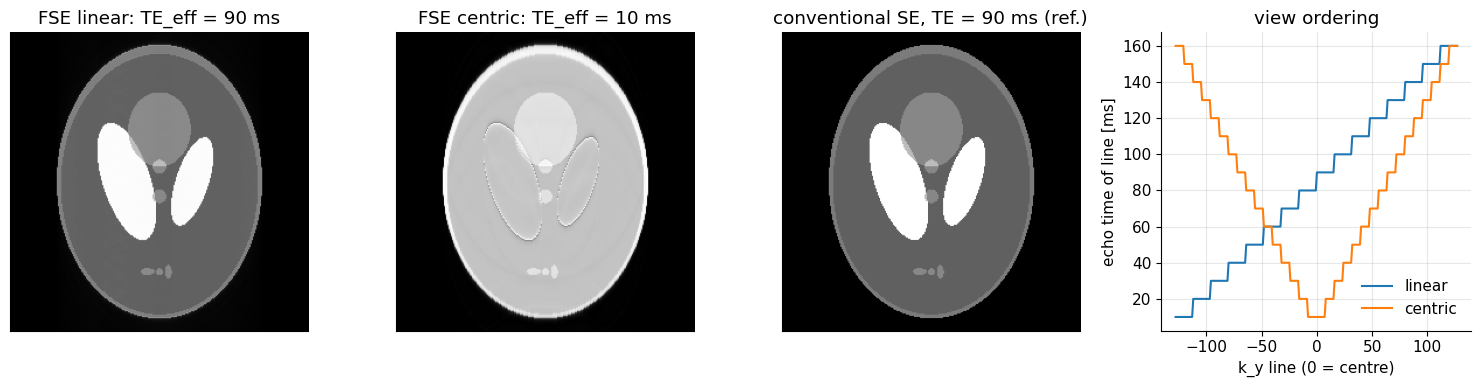

In [3]:
def fse_echo_index(N_PE, ETL, order="linear"):
    """Return, for every PE line (index 0..N_PE-1, centre at N_PE//2), the echo number 1..ETL."""
    lines = np.arange(N_PE)
    per_echo = N_PE // ETL                                     # lines acquired by each echo
    if order == "linear":                                      # bottom -> top
        return lines // per_echo + 1
    if order == "centric":                                     # centre first, then outwards
        rank = np.argsort(np.argsort(np.abs(lines - N_PE // 2) + 1e-3 * lines))
        return rank // per_echo + 1
    raise ValueError(order)

def fse_acquire(ph, TR, t_esp, ETL, order="linear"):
    """Simulate FSE k-space of a tissue phantom: line k_y gets weight exp(-t_n/T2) of its echo n."""
    N = ph["M0"].shape[0]
    echo = fse_echo_index(N, ETL, order)
    K = np.zeros((N, N), complex)
    base = ph["M0"] * (1 - np.exp(-TR / ph["T1"]))             # T1 recovery (TR >> TE assumed)
    for n in range(1, ETL + 1):
        img_n = base * np.exp(-n * t_esp / ph["T2"])            # whole image as it looks at echo n
        rows = echo == n
        K[rows] = mt.fft2c(img_n)[rows]                         # keep only the lines echo n acquires
    return K, echo

ph = mt.tissue_phantom(256)
TR, t_esp, ETL = 4.0, 10e-3, 16
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, order in zip(axes[:2], ["linear", "centric"]):
    K, echo = fse_acquire(ph, TR, t_esp, ETL, order)
    TE_eff = echo[128] * t_esp
    mt.show_image(mt.ifft2c(K), ax=ax, title=f"FSE {order}: TE_eff = {TE_eff*1e3:.0f} ms")
ref = mt.spin_echo_signal(90e-3, TR, ph["T1"], ph["T2"], ph["M0"])
mt.show_image(ref, ax=axes[2], title="conventional SE, TE = 90 ms (ref.)")
for order in ["linear", "centric"]:
    axes[3].plot(np.arange(256) - 128, fse_echo_index(256, ETL, order) * t_esp * 1e3, label=order)
axes[3].set_xlabel("k_y line (0 = centre)"); axes[3].set_ylabel("echo time of line [ms]"); axes[3].legend()
axes[3].set_title("view ordering")
plt.tight_layout(); plt.show()

The linear-order FSE looks almost identical to a conventional spin echo with $TE=90$ ms (bright CSF, T2 contrast) but was acquired 16× faster. With centric ordering the same data are PD-weighted: the *ordering*, not the train itself, selects the contrast.

Now the blurring. For **single-shot** FSE (all 128 lines in one train, $t_{esp}=5$ ms), compare the modulation function and the PSF for white-matter-like ($T_2=80$ ms) and CSF-like ($T_2=2$ s) tissue:

centric single-shot, T2 =    80 ms: PSF FWHM ≈ 5 pixels
centric single-shot, T2 =  2000 ms: PSF FWHM ≈ 1 pixels


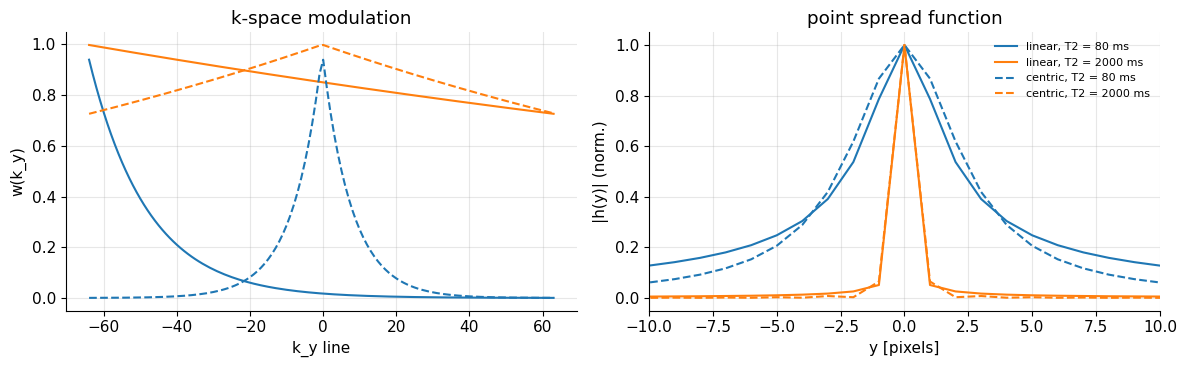

In [4]:
N_PE, t_esp = 128, 5e-3
ky = np.arange(N_PE) - N_PE // 2
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for order, ls in [("linear", "-"), ("centric", "--")]:
    t_line = fse_echo_index(N_PE, N_PE, order) * t_esp          # ETL = N_PE: one line per echo
    for T2, col in [(0.08, "C0"), (2.0, "C1")]:
        w = np.exp(-t_line / T2)
        h = np.abs(mt.ifftc(w)); h /= h.max()
        axes[0].plot(ky, w, ls, color=col, label=f"{order}, T2 = {T2*1e3:.0f} ms")
        axes[1].plot(ky, h, ls, color=col, label=f"{order}, T2 = {T2*1e3:.0f} ms")
        fwhm = np.sum(h >= 0.5)
        if order == "centric":
            print(f"centric single-shot, T2 = {T2*1e3:5.0f} ms: PSF FWHM ≈ {fwhm} pixels")
axes[0].set_xlabel("k_y line"); axes[0].set_ylabel("w(k_y)"); axes[0].set_title("k-space modulation")
axes[1].set_xlim(-10, 10); axes[1].set_xlabel("y [pixels]"); axes[1].set_ylabel("|h(y)| (norm.)")
axes[1].set_title("point spread function"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

For CSF the weighting is almost flat and the PSF is a sharp single pixel. For white matter in a centric single-shot train the outer lines (acquired 0.6 s after excitation) are almost zero, which broadens the PSF to several pixels: **T2 blurring**. Linear ordering puts the weak late echoes at one edge of k-space only, giving an asymmetric but narrower PSF (and a long $TE_{eff}$). Let's see it on the phantom:

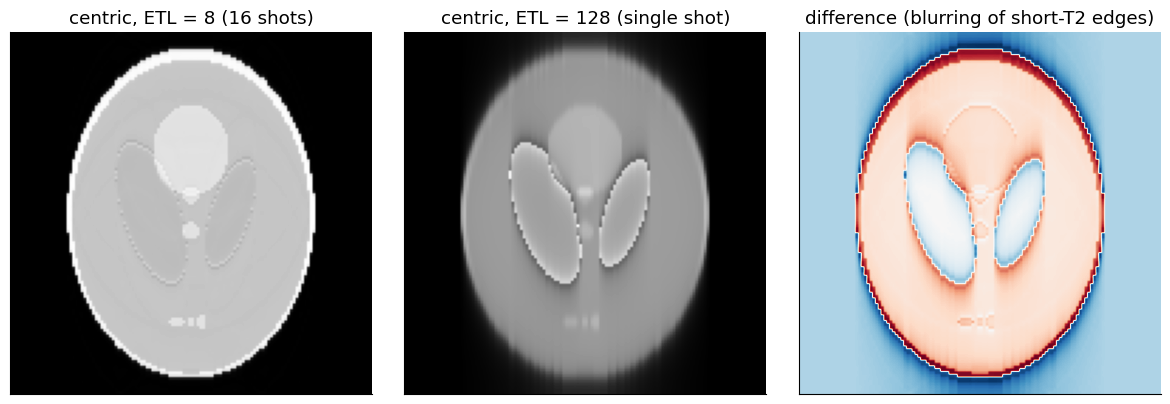

In [5]:
ph128 = mt.tissue_phantom(128)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
K16, _ = fse_acquire(ph128, 4.0, 5e-3, 8, "centric")       # ETL 8 = short train, little blur
K128, _ = fse_acquire(ph128, 4.0, 5e-3, 128, "centric")    # single shot, strong blur
mt.show_image(mt.ifft2c(K16), ax=axes[0], title="centric, ETL = 8 (16 shots)")
mt.show_image(mt.ifft2c(K128), ax=axes[1], title="centric, ETL = 128 (single shot)")
mt.show_image(np.abs(mt.ifft2c(K16)) - np.abs(mt.ifft2c(K128)) * np.abs(mt.ifft2c(K16)).max() / np.abs(mt.ifft2c(K128)).max(),
              ax=axes[2], title="difference (blurring of short-T2 edges)", cmap="RdBu_r")
plt.tight_layout(); plt.show()

The single-shot image is blurred along the vertical (PE) direction for the short-T2 tissues while the long-T2 CSF regions stay sharp. Real single-shot FSE (HASTE/SSFSE) uses half-Fourier (fewer echoes) and short echo spacings to limit this.

### 1.4 Trade-offs

Pros
* Fast (factor $ETL$ fewer repetitions)
* SNR efficient: refocused spin echoes, insensitive to $\Delta B_0$ (no T2* decay, little distortion)
* Supports multiple contrasts by manipulating $TE_{eff}$ (view ordering), even several contrasts from one train ("dual-echo" PD/T2)

Cons
* Long echo train lengths lead to **T2 blurring** or other k-space-modulation artifacts (ringing, edge enhancement)
* **High SAR** from the many 180° refocusing pulses ([MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)). SAR of a pulse scales with $\theta^2$, so a 180° pulse deposits 4× the energy of a 90° pulse.
* Fat appears brighter than in conventional SE (rapid refocusing disrupts J-coupling dephasing of fat), so fat suppression is often added
* Fewer slices per TR (each slice occupies $\approx ETL\cdot t_{esp}$ of the TR)

> **🔧 Engineering reality:** To control SAR at 3 T and to make long 3D trains possible, modern FSE uses **refocusing flip angles below 180°** (e.g. 120°, or variable-flip-angle trains in 3D FSE: SPACE, CUBE, VISTA). With θ < 180° part of the signal travels via stimulated-echo pathways (temporarily stored as $M_z$, where it decays with T1, not T2). This slows the decay of the train, allowing ETLs of 100–250 for 3D isotropic T2/FLAIR imaging, but makes the contrast deviate slightly from a pure T2 decay.

## 2. Echo-planar imaging (EPI)

EPI reads out **many k-space lines sequentially after a single excitation**, using a train of **gradient echoes**: the readout gradient alternates its sign, and every lobe traverses one line of k-space. It is the fastest sequence (a 64 × 64 image in ~40 ms) and is the workhorse of **diffusion-weighted imaging** and **functional MRI (fMRI)**.

### 2.1 Pulse sequence and k-space diagram

![EPI pulse sequence: an alternating readout gradient Gx, small phase-encode "blips" on Gy between lobes, and continuous data acquisition (DAQ). Right: the zig-zag (raster) k-space trajectory.](../images/pulse_sequence-diagram-EPI.png)

Let's build this gradient waveform numerically, integrate it to get $\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)d\tau$, and check that it produces the raster trajectory. Realistic values: $FOV$ = 24 cm, $N$ = 64, max gradient 25 mT/m, slew rate 150 T/m/s.

readout flat top 0.251 ms, ramps 0.167 ms, echo spacing t_esp = 0.634 ms
total echo-train duration ≈ 40.6 ms;  kx range -133..131 1/m (k_max = 133)


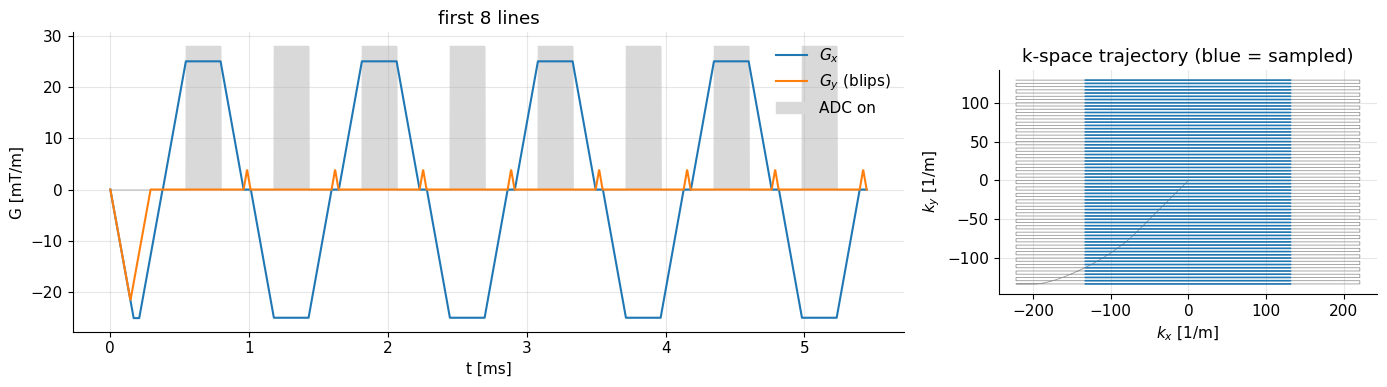

In [6]:
# Build an EPI gradient waveform (trapezoids) and integrate it to the k-space trajectory
dt = 2e-6                     # time step [s]
FOV, N = 0.24, 64             # [m], matrix
G_max, SR = 25e-3, 150.0      # [T/m], [T/m/s]
k_max = N / (2 * FOV)         # [1/m]
dk = 1 / FOV                  # [1/m]

def trapezoid(area, G_amp, SR, dt):
    """Gradient trapezoid with given area [T s/m] (sign included), amplitude limit and slew rate."""
    sgn, area = np.sign(area), abs(area)
    t_ramp = G_amp / SR
    t_flat = max(area / G_amp - t_ramp, 0.0)
    if t_flat == 0.0:                                  # triangle: lower amplitude
        G_amp = np.sqrt(area * SR); t_ramp = G_amp / SR
    n_r, n_f = int(np.ceil(t_ramp / dt)), int(round(t_flat / dt))
    ramp = np.linspace(0, 1, n_r, endpoint=False)
    w = np.concatenate([ramp, np.ones(n_f), ramp[::-1]]) * G_amp
    return sgn * w * area / (np.sum(w) * dt)          # rescale to the exact area

area_read = 2 * k_max / mt.GAMMA_BAR                   # flat-top area that traverses one line [T s/m]
t_ramp = G_max / SR                                    # ramp time [s]
t_flat = area_read / G_max                             # flat-top (sampling) time [s]
n_r, n_f = int(round(t_ramp / dt)), int(round(t_flat / dt))
read_lobe = np.concatenate([np.linspace(0, 1, n_r, endpoint=False), np.ones(n_f), np.linspace(1, 0, n_r, endpoint=False)]) * G_max
adc_lobe = np.concatenate([np.zeros(n_r), np.ones(n_f), np.zeros(n_r)])
blip = trapezoid(dk / mt.GAMMA_BAR, G_max, SR, dt)     # small triangle: Delta k_y = 1/FOV
# prephasers: go to (-k_max, -k_max); the x-prephaser also cancels the area of the first ramp-up
pre_x = trapezoid(-(k_max + mt.GAMMA_BAR * G_max * t_ramp / 2) / mt.GAMMA_BAR, G_max, SR, dt)
pre_y = trapezoid(-k_max / mt.GAMMA_BAR, G_max, SR, dt)

n_pre = max(len(pre_x), len(pre_y))
segs_x, segs_y, segs_adc = [np.zeros(n_pre)], [np.zeros(n_pre)], [np.zeros(n_pre)]
segs_x[0][:len(pre_x)] = pre_x; segs_y[0][:len(pre_y)] = pre_y
for line in range(N):
    sgn = 1 if line % 2 == 0 else -1                   # alternate the readout polarity
    segs_x.append(sgn * read_lobe); segs_y.append(np.zeros_like(read_lobe)); segs_adc.append(adc_lobe)
    if line < N - 1:                                   # blip between lobes (simplification: real EPI
        segs_x.append(np.zeros_like(blip))             #  overlaps the blip with the ramps)
        segs_y.append(blip); segs_adc.append(np.zeros_like(blip))
Gx, Gy, adc = map(np.concatenate, (segs_x, segs_y, segs_adc))
kx = mt.GAMMA_BAR * np.cumsum(Gx) * dt                 # k(t) = gamma_bar * integral of G
ky = mt.GAMMA_BAR * np.cumsum(Gy) * dt
t = np.arange(len(Gx)) * dt

t_esp = (len(read_lobe) + len(blip)) * dt          # time between line centres [s]
print(f"readout flat top {t_flat*1e3:.3f} ms, ramps {t_ramp*1e3:.3f} ms, echo spacing t_esp = {t_esp*1e3:.3f} ms")
print(f"total echo-train duration ≈ {N*t_esp*1e3:.1f} ms;  kx range {kx[adc>0].min():.0f}..{kx[adc>0].max():.0f} 1/m (k_max = {k_max:.0f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
sl = t < 8 * t_esp + n_pre * dt
axes[0].plot(t[sl] * 1e3, Gx[sl] * 1e3, label="$G_x$")
axes[0].plot(t[sl] * 1e3, Gy[sl] * 1e3, label="$G_y$ (blips)")
axes[0].fill_between(t[sl] * 1e3, 0, adc[sl] * 28, color="0.85", label="ADC on", zorder=0)
axes[0].set_xlabel("t [ms]"); axes[0].set_ylabel("G [mT/m]"); axes[0].legend(loc="upper right"); axes[0].set_title("first 8 lines")
axes[1].plot(kx, ky, lw=0.6, color="0.6")
axes[1].plot(np.where(adc > 0, kx, np.nan), np.where(adc > 0, ky, np.nan), lw=1.2)
axes[1].set_xlabel("$k_x$ [1/m]"); axes[1].set_ylabel("$k_y$ [1/m]"); axes[1].set_title("k-space trajectory (blue = sampled)")
axes[1].set_aspect("equal")
plt.tight_layout(); plt.show()

The integral of the alternating readout lobes sweeps $k_x$ back and forth, each blip steps $k_y$ by $\Delta k_y = 1/FOV$, and the prephasers start the train at the corner $(-k_{max},-k_{max})$. With realistic hardware the echo spacing is about 0.63 ms, so 64 lines take ~41 ms. Note how much of the time is spent on **ramps**: the slew rate, not just the amplitude, limits EPI speed. (Clinical EPI also samples during the ramps, "ramp sampling", and regrids the data.)

### 2.2 Sequence parameters

* **Echo spacing** ($t_{esp}$): time between successive readouts (gradient echoes), i.e. between adjacent $k_y$ lines.
* **Echo train length** ($ETL$): number of readouts (k-space lines) acquired after one excitation. Single-shot EPI: $ETL = N_{PE}$. Segmented/multi-shot EPI: $ETL = N_{PE}/N_{shots}$, with interleaved lines.
* **TE**: the time at which the line closest to the centre of k-space is acquired. For a single-shot linear EPI, $TE \approx$ (time to the start of the train) $+\ \tfrac{N_{PE}}{2}t_{esp}$.

### 2.3 Why EPI is so sensitive to off-resonance

Off-resonant spins (field inhomogeneity $\Delta f_r$, or chemical shift $\Delta f_{cs}$ of fat) accumulate an extra phase $-2\pi\Delta f\,t$ (left-handed precession, $M_{xy}\propto e^{-i2\pi\Delta f t}$). What matters is how this phase grows **from one k-space sample to the next** along each direction:

* **Readout direction:** adjacent $k_x$ samples are $\Delta t$ apart (a few µs). The bandwidth per pixel is $BW_{pix,read}=1/(N_x\Delta t)$, typically 1–4 kHz/pixel in EPI: a 100 Hz offset shifts by only 0.03–0.1 pixel. Negligible.
* **Phase-encode direction:** adjacent $k_y$ lines are $t_{esp}$ apart (≈ 0.5 ms, about 100× longer!). The effective bandwidth per pixel along PE is tiny:

$$BW_{pix,PE} = \frac{1}{N_{PE}\, t_{esp}}.$$

In words: the whole echo train ($N_{PE}t_{esp}$, tens of ms) plays the role of the "readout" in the PE direction, so its bandwidth per pixel is only tens of Hz,

where $N_{PE}$ is the number of lines in the echo train (per shot) and $t_{esp}$ [s] the echo spacing.

**Derivation of the pixel shift.** Let line number $p$ ($k_y = p\,\Delta k_y$, $p=-N/2,\dots,N/2-1$) be acquired at time $t_p = TE + p\,t_{esp}$. A spin at $y_0$ with off-resonance $\Delta f$ contributes to line $p$

$$m\,e^{-i2\pi k_y y_0}\;e^{-i2\pi\Delta f\,(TE + p\,t_{esp})} = m\,e^{-i2\pi\Delta f TE}\;e^{-i2\pi k_y \left(y_0 + \Delta f\, t_{esp}/\Delta k_y\right)} .$$

In words: the extra phase grows linearly with the line number $p = k_y/\Delta k_y$, i.e. linearly with $k_y$, and a linear phase in k-space is a **shift** in image space (shift theorem, [RM4](../refreshers/RM4_Fourier_Properties.ipynb)). The spin appears at $y_0 + \Delta y$ with

$$\Delta y = \frac{\Delta f\,t_{esp}}{\Delta k_y} = \Delta f\, t_{esp}\, FOV_y \qquad\Longleftrightarrow\qquad \frac{\Delta y}{\delta_y} = \Delta f\cdot N_{PE}\cdot t_{esp} = \frac{\Delta f}{BW_{pix,PE}},$$

where $\Delta k_y = 1/FOV_y$ is the k-space line spacing, $\delta_y = FOV_y/N_{PE}$ the pixel size and $\Delta y$ [m] the displacement. The sign of the shift depends on the blip direction (bottom-up vs top-down traversal), which is why "blip-up/blip-down" pairs are used to measure and correct distortion.

In [7]:
# Pixel shifts for typical EPI and conventional parameters
cases = [  # name, Delta f [Hz], N_PE, t_esp [s]
    ("EPI, 1 ppm field error @3T", 128, 64, 0.5e-3),
    ("EPI, fat @3T (-3.5 ppm)", mt.ppm_to_hz(-3.5, 3.0), 64, 0.5e-3),
    ("EPI, fat @1.5T", mt.ppm_to_hz(-3.5, 1.5), 64, 0.5e-3),
    ("EPI 128 lines, 1 ppm @3T", 128, 128, 0.7e-3),
    ("same with parallel imaging R=2", 128, 64, 0.7e-3),
]
for name, df, Npe, tesp in cases:
    print(f"{name:34s}: BW_pix,PE = {1/(Npe*tesp):5.1f} Hz/pixel -> shift = {df*Npe*tesp:+6.1f} pixels")
BW_read = 250e3; Nx = 64
print(f"{'readout direction (BW 250 kHz, 64 px)':34s}: BW_pix,read = {BW_read/Nx:6.0f} Hz/pixel -> 128 Hz shifts {128/(BW_read/Nx):.3f} pixels")

EPI, 1 ppm field error @3T        : BW_pix,PE =  31.2 Hz/pixel -> shift =   +4.1 pixels
EPI, fat @3T (-3.5 ppm)           : BW_pix,PE =  31.2 Hz/pixel -> shift =  -14.3 pixels
EPI, fat @1.5T                    : BW_pix,PE =  31.2 Hz/pixel -> shift =   -7.2 pixels
EPI 128 lines, 1 ppm @3T          : BW_pix,PE =  11.2 Hz/pixel -> shift =  +11.5 pixels
same with parallel imaging R=2    : BW_pix,PE =  22.3 Hz/pixel -> shift =   +5.7 pixels
readout direction (BW 250 kHz, 64 px): BW_pix,read =   3906 Hz/pixel -> 128 Hz shifts 0.033 pixels


A field error of 1 ppm (normal near the sinuses or ear canals at 3 T) shifts EPI pixels by several pixels; fat is displaced by ~14 pixels at 3 T. That is why **fat suppression is mandatory in EPI**, and why EPI images of the frontal lobe look stretched or compressed. Note the last line: parallel imaging with $R=2$ halves the number of lines per train (with the same $t_{esp}$) and halves the distortion, one of its most important uses in EPI ([H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)).

Now a full simulation. Each k-space line $p$ is computed from the object "as it looks at time $t_p$": $m(\vec r)\,e^{-i2\pi\Delta f(\vec r)t_p}e^{-t_p/T_2^*(\vec r)}$. We put a susceptibility "hot spot" (+150 Hz, like the frontal sinus) at the top of the phantom and a fat ring (scalp) at −440 Hz (3 T).

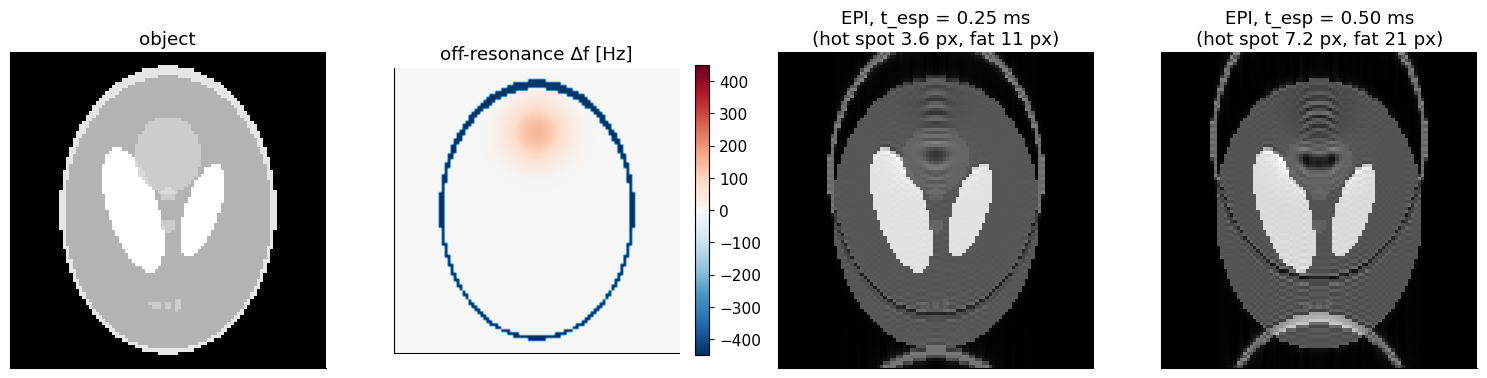

In [8]:
def epi_acquire(m, df_map, t_esp, TE, T2s=None, shift_sign=+1):
    """Single-shot EPI simulation: line p (0..N-1, centre N//2) is acquired at TE + (p - N//2) t_esp.

    m: complex image; df_map: off-resonance [Hz]; T2s: T2* map [s] or None.
    Readout-direction effects (µs between samples) are neglected."""
    N = m.shape[0]
    K = np.zeros_like(m, dtype=complex)
    for p in range(N):
        t_p = TE + shift_sign * (p - N // 2) * t_esp
        w = m * np.exp(-1j * 2 * np.pi * df_map * t_p)
        if T2s is not None:
            w = w * np.exp(-t_p / T2s)
        K[p] = mt.fft2c(w)[p]          # only line p is measured at time t_p
    return K

N = 96
ph = mt.tissue_phantom(N)
m = ph["M0"].astype(complex)
yy, xx = np.mgrid[1:-1:N * 1j, -1:1:N * 1j]
df_b0 = 150 * np.exp(-((xx) ** 2 + (yy - 0.55) ** 2) / (2 * 0.15 ** 2))   # [Hz] susceptibility hot spot
fat = ph["labels"] == 1
df_tot = df_b0 + np.where(fat, mt.ppm_to_hz(-3.5, 3.0), 0.0)               # fat at -447 Hz (3 T)
T2s = np.where(ph["labels"] == 4, 0.2, 0.04)                               # T2* [s]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
mt.show_image(m, ax=axes[0], title="object")
im = axes[1].imshow(df_tot, cmap="RdBu_r", vmin=-450, vmax=450); axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("off-resonance Δf [Hz]"); plt.colorbar(im, ax=axes[1], fraction=0.046)
for ax, tesp in zip(axes[2:], [0.25e-3, 0.5e-3]):
    K = epi_acquire(m, df_tot, tesp, 30e-3, T2s)
    mt.show_image(mt.ifft2c(K), ax=ax, title=f"EPI, t_esp = {tesp*1e3:.2f} ms\n(hot spot {150*N*tesp:.1f} px, fat {447*N*tesp:.0f} px)")
plt.tight_layout(); plt.show()

The fat ring is displaced along the PE (vertical) direction and wraps around, and the region near the hot spot is distorted (signal piles up where the shift compresses the image and thins out where it stretches it). Doubling $t_{esp}$ doubles all shifts. The faint ripples come from T2* decay during the ~50 ms train (**T2* blurring**, the gradient-echo analogue of FSE's T2 blurring, on top of the signal dropout that T2* causes at long TE).

> **🔧 Engineering reality:** The echo spacing is limited by the gradient system: higher amplitude and slew rate give shorter lobes. But fast switching induces electric fields in the body that can cause **peripheral nerve stimulation (PNS)** ([Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb), [MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)), so EPI often runs at the PNS limit rather than the hardware limit. EPI is also the loudest sequence (the readout oscillates at ~1 kHz, right in the range of human hearing), and scanners forbid echo spacings that would excite mechanical resonances of the gradient coil.

### 2.4 Nyquist (N/2) ghosting

Odd lines are acquired with a positive readout gradient, even lines with a negative one (right-to-left in k-space). Any imperfection that differs between the two polarities (eddy currents, gradient delays, a slight timing offset of the ADC) makes odd and even lines inconsistent: typically a constant phase and/or a shift of the echo along $k_x$ (a linear phase in $x$). The simplest model is a constant phase error $\phi$ on every other line:

$$M_{meas}(k_x, k_y^{(p)}) = M(k_x,k_y^{(p)})\cdot\begin{cases}1 & p \text{ even}\\ e^{i\phi} & p\text{ odd}\end{cases} = M\cdot\left[\frac{1+e^{i\phi}}{2} + \frac{1-e^{i\phi}}{2}(-1)^p\right].$$

In words: we can split the "every-other-line" error into an average part and a part that alternates in sign from line to line,

and $(-1)^p = e^{i\pi p} = e^{-i2\pi k_y (FOV/2)}$ is a linear phase in $k_y$ that shifts the image by **half the FOV** (shift theorem). So the image is

$$m_{meas}(y) = \frac{1+e^{i\phi}}{2}\,m(y) + \frac{1-e^{i\phi}}{2}\,m\!\left(y - \tfrac{FOV}{2}\right),$$

a weakened true image plus a **ghost shifted by FOV/2** with relative amplitude $|\sin(\phi/2)|$ (and $|\tan(\phi/2)|$ relative to the main image),

where $\phi$ [rad] is the odd/even phase mismatch and $m(y-FOV/2)$ is the image shifted by half the field of view (wrapping around).

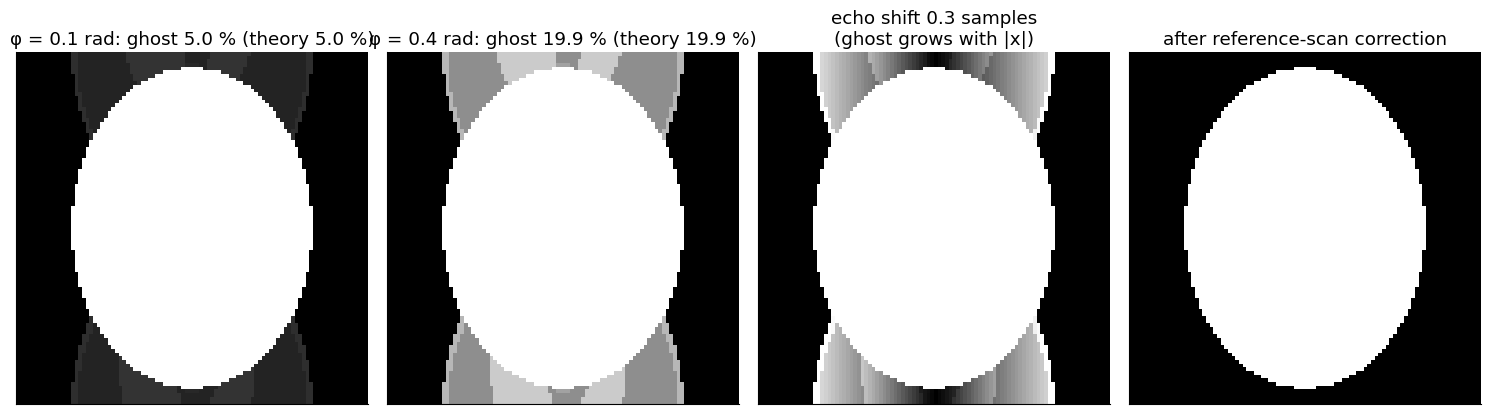

In [9]:
# Simulate N/2 ghosts: constant phase error, and a k_x shift (linear phase in x) between odd and even lines
K0 = mt.fft2c(m)
x_pix = np.arange(N) - N // 2
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, phi in zip(axes[:2], [0.1, 0.4]):
    Kg = K0.copy(); Kg[1::2] *= np.exp(1j * phi)
    img = mt.ifft2c(Kg)
    ghost_meas = np.linalg.norm(img - (1 + np.exp(1j * phi)) / 2 * m) / np.linalg.norm(m)
    mt.show_image(img, ax=ax, vmax=0.25, title=f"φ = {phi} rad: ghost {ghost_meas*100:.1f} % "
                  f"(theory {abs(np.sin(phi/2))*100:.1f} %)")
# echo shift: odd lines' echo displaced by 0.3 samples along kx -> linear phase along x in hybrid (x, ky) space
hyb = mt.ifftc(K0, axis=1)                                    # x-ky hybrid space
hyb[1::2] *= np.exp(1j * 2 * np.pi * 0.3 * x_pix / N)[None, :]
img_lin = mt.ifftc(hyb, axis=0)
mt.show_image(img_lin, ax=axes[2], vmax=0.25, title="echo shift 0.3 samples\n(ghost grows with |x|)")
# correction with a reference scan: the k_y = 0 line is acquired twice WITHOUT blips, once with each
# readout polarity; their phase difference versus x is the odd/even error, which we fit and remove
hyb_true = mt.ifftc(K0, axis=1)
ref_even = hyb_true[N // 2]
ref_odd = hyb_true[N // 2] * np.exp(1j * 2 * np.pi * 0.3 * x_pix / N)      # same error as the odd lines
dphi_x = np.angle(ref_odd * np.conj(ref_even))                             # phase difference per x [rad]
sig = np.abs(ref_even) > 0.1 * np.abs(ref_even).max()                       # fit only where there is signal
fit = np.polyfit(x_pix[sig], np.unwrap(dphi_x[sig]), 1)
hyb_c = hyb.copy(); hyb_c[1::2] *= np.exp(-1j * np.polyval(fit, x_pix))[None, :]
mt.show_image(mt.ifftc(hyb_c, axis=0), ax=axes[3], vmax=0.25, title="after reference-scan correction")
plt.tight_layout(); plt.show()

(The display is windowed to 25 % of the maximum so that the ghosts are visible.) The measured ghost fraction matches $|\sin(\phi/2)|$. A shift of the odd echoes gives a ghost whose intensity grows with $|x|$ (a linear phase). The standard fix is a short **reference (navigator) scan** of a few lines without blips, from which the odd/even phase difference is estimated (here: a linear fit across $x$) and removed before the FFT.

### 2.5 Trade-offs

Pros
* Extremely fast, supporting **single-shot** imaging (a full 2D image per excitation, ~50–100 ms): freezes motion, enables fMRI (a whole brain every 1–2 s) and diffusion imaging (motion-insensitive)

Cons
* Susceptible to chemical shift and susceptibility **displacement artifacts** (low $BW_{pix,PE}$)
* Sensitive to gradient fidelity artifacts (e.g. **Nyquist/N/2 ghosting**)
* Long echo train lengths lead to **T2\* blurring** and signal dropout
* Low resolution in single shot (typically 2–3 mm in plane); cures: segmentation (multi-shot), readout segmentation, parallel imaging

## 3. Fast gradient-echo sequences

The basic gradient-echo (GRE) sequence ([Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)) uses no refocusing pulse, so TR can be very short (2–10 ms), with small flip angles. When $TR \ll T_2$, transverse magnetization is still present when the next RF pulse arrives, and what we do with it defines the sequence family:

| What happens to leftover $M_{xy}$ at the end of TR | Family | Typical contrast |
|---|---|---|
| destroyed every TR (spoiled) | spoiled GRE (FLASH, SPGR) | T1 (or PD at low θ; T2* at long TE) |
| kept, but dephased by an unbalanced gradient (2π per voxel per TR); signal read just after the pulse | SSFP-FID (FISP, GRASS) | mixed T1/T2 ("T2/T1"-ish, more T1) |
| as above, but the echo formed just *before* the next pulse is read | SSFP-echo (PSIF) | strongly T2-weighted |
| kept and fully refocused: all gradients balanced (net zero area per TR) | balanced SSFP (TrueFISP, FIESTA, bFFE) | T2/T1, very high SNR |

The basic gradient-echo sequence is typically a **spoiled** gradient echo: the transverse magnetization is spoiled before the next RF pulse.

### 3.1 Spoiler (crusher) gradients

A large, unbalanced gradient creates a phase that varies by several cycles across each voxel. The isochromats (spin packets) inside the voxel point in all directions and their vector sum, the voxel signal, is approximately zero. However, the net magnetization is **not truly eliminated**: each isochromat still has its own transverse component, and later gradients (or RF pulses) can refocus it into echoes. With a *fixed* spoiler every TR, these "hidden" components build up into a steady state that still contributes signal.

### 3.2 RF spoiling

The RF axis of rotation (the RF phase $\varphi_n$) is changed every TR. Magnetization from previous TRs then no longer adds coherently. An effective scheme is **quadratic phase incrementation**:

$$\varphi_n = \varphi_{n-1} + n\,\varphi_0 \quad\Longleftrightarrow\quad \varphi_n = \tfrac12 n(n+1)\varphi_0,\qquad \varphi_0 = 117^\circ,$$

In words: the phase increment itself grows by $\varphi_0$ every TR,

where $n$ is the TR index and $\varphi_0$ the increment (117° or 50° are standard, Zur et al. 1991). The receiver phase follows $\varphi_n$ so the wanted signal is demodulated consistently.

The ideal spoiled steady state (derivation in [Basic Contrast Mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb)) is

$$S_{SPGR} = M_0 \sin\theta\,\frac{1 - E_1}{1 - \cos\theta\, E_1}\,e^{-TE/T_2^*},\qquad E_1=e^{-TR/T_1}.$$

In words: each pulse converts a fraction $\sin\theta$ of the steady-state $M_z$ into signal; that steady state balances T1 recovery $(1-E_1)$ against the loss $\cos\theta E_1$ per TR,

where $\theta$ is the flip angle, $TR$, $TE$ [s] and $T_1$, $T_2^*$ [s] as usual. The signal is maximal at the **Ernst angle** $\theta_E=\arccos E_1$.

Let's test both spoiling methods with an **isochromat simulation**: 100 spin packets per voxel, each receiving an extra precession $2\pi j/100$ per TR from the spoiler gradient, with full Bloch rotations and relaxation, run until steady state.

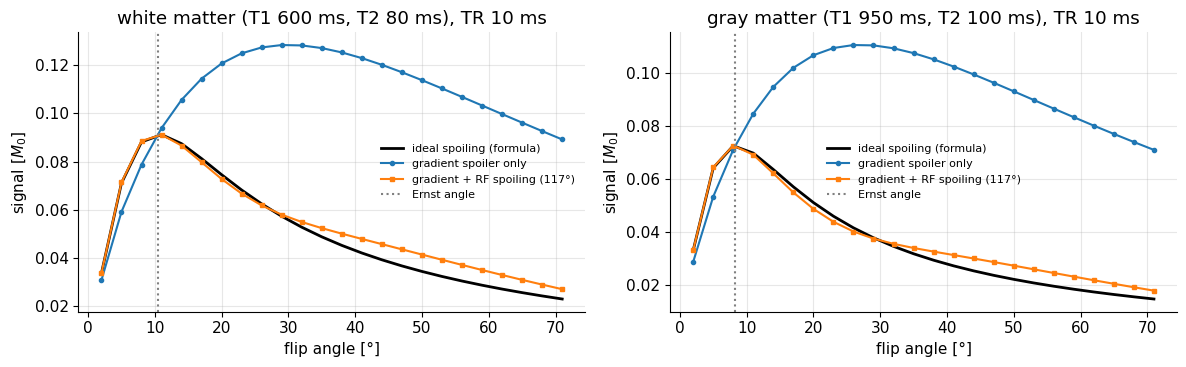

In [10]:
def rf_rotation(theta, phase=0.0):
    """3x3 rotation of an RF pulse with flip theta [rad] about the axis at angle `phase` in the xy-plane.

    Left-handed (Bloch) convention as in mri_tools: rotation_matrix(axis, -theta)."""
    return mt.rotation_matrix([np.cos(phase), np.sin(phase), 0.0], -theta)

def gre_isochromat_sim(thetas, TR, T1, T2, n_tr=600, n_iso=100, rf_spoil=False, phi0=np.radians(117),
                       df=0.0, spoil_cycles=1.0):
    """Steady-state signals of a GRE with an unbalanced (spoiler) gradient, via isochromats.

    thetas: flip angles [rad] (array); TR, T1, T2 [s]; spoil_cycles: dephasing across the voxel per TR [cycles].
    rf_spoil: quadratic RF phase increments phi0. df: extra off-resonance [Hz].
    Returns (S_plus, S_minus): |mean Mxy| just after the pulse (FID) and just before the next pulse (echo)."""
    thetas = np.atleast_1d(thetas)
    M = np.zeros((len(thetas), n_iso, 3)); M[..., 2] = 1.0
    beta = 2 * np.pi * (spoil_cycles * np.arange(n_iso) / n_iso + df * TR)   # precession per TR [rad]
    E1, E2 = np.exp(-TR / T1), np.exp(-TR / T2)
    R0 = np.stack([rf_rotation(t) for t in thetas])                          # RF about x
    phase = 0.0
    for n in range(n_tr):
        if rf_spoil:
            phase += n * phi0
            Rz_p, Rz_m = mt.Rz(phase), mt.Rz(-phase)
            R = np.einsum("ij,fjk,kl->fil", Rz_p, R0, Rz_m)                   # rotate the RF axis by `phase`
        else:
            R = R0
        M = np.einsum("fij,fsj->fsi", R, M)
        mxy = (M[..., 0] + 1j * M[..., 1]) * np.exp(-1j * phase)              # receiver follows RF phase
        S_plus = np.abs(mxy.mean(axis=1))
        mxy_all = (M[..., 0] + 1j * M[..., 1]) * np.exp(-1j * beta) * E2      # precess + T2 during TR
        M = np.stack([mxy_all.real, mxy_all.imag, 1 + (M[..., 2] - 1) * E1], axis=-1)
        S_minus = np.abs((M[..., 0] + 1j * M[..., 1]).mean(axis=1))
    return S_plus, S_minus

TR = 10e-3
flips = np.radians(np.arange(2, 72, 3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, (name, T1, T2) in zip(axes, [("white matter", 0.6, 0.08), ("gray matter", 0.95, 0.10)]):
    s_grad, _ = gre_isochromat_sim(flips, TR, T1, T2)
    s_rf, _ = gre_isochromat_sim(flips, TR, T1, T2, rf_spoil=True)
    ax.plot(np.degrees(flips), mt.spoiled_gre_signal(flips, 0, TR, T1, np.inf), "k-", lw=2, label="ideal spoiling (formula)")
    ax.plot(np.degrees(flips), s_grad, "o-", ms=3, label="gradient spoiler only")
    ax.plot(np.degrees(flips), s_rf, "s-", ms=3, label="gradient + RF spoiling (117°)")
    ax.axvline(np.degrees(mt.ernst_angle(TR, T1)), color="0.5", ls=":", label="Ernst angle")
    ax.set_xlabel("flip angle [°]"); ax.set_ylabel("signal [$M_0$]"); ax.set_title(f"{name} (T1 {T1*1e3:.0f} ms, T2 {T2*1e3:.0f} ms), TR {TR*1e3:.0f} ms")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

With a spoiler gradient alone, the leftover transverse magnetization re-enters the signal and the "spoiled" sequence behaves very differently from the formula at larger flip angles (more signal, and a T2 dependence). Adding 117° RF spoiling brings the simulation close to the ideal curve. Residual deviations at large flip angles are known, which is one reason quantitative T1 mapping with spoiled GRE needs care.

### 3.3 Types of fast gradient-echo sequences

**Spoiled gradient echo (SPGR) / fast low-angle shot (FLASH)**
* Aims to fully spoil transverse magnetization every TR
* Both gradient and RF spoiling are used
* T1-weighted contrast at moderate-to-large flip angles and short TE. *(The original says "pure T1 weighted"; more precisely: PD-weighted at small flip angles $\theta \ll \theta_E$, T1-weighted above the Ernst angle, plus T2\* weighting if TE is long.)*

$$S_{SPGR} \propto M_0 \sin \theta\, \frac{1 - \exp(-TR/T_1)}{1 - \cos \theta \exp(-TR/T_1)}$$

**Gradient-recalled acquisition in the steady state (GRASS) / fast imaging with steady-state precession (FISP)**, generically **SSFP-FID**
* Allows the residual transverse magnetization to contribute in the next TR
* Rewinds the phase-encoding gradient (so the steady state does not depend on the PE step); the readout/slice gradients leave a net dephasing per TR
* **No** RF spoiling. *(The original says "RF spoiling used"; that would destroy exactly the coherence these sequences rely on.)*
* Adds T2 dependence to the T1 weighting: tissues with long T2 (fluid) are brighter than in SPGR

**Steady-state free precession echo (SSFP-echo) / time-reversed FISP (PSIF)**
* Uses gradients to refocus, in the next TR, signal that was dephased by the (unbalanced) gradient: an echo forms just before the next RF pulse (PSIF = FISP written backwards, because the timing is mirrored)
* Gradient spoiling within a TR, refocused in later TRs; no RF spoiling
* Strongly **T2-weighted** contrast (the echo has lived for nearly two TRs plus stimulated-echo paths). *(The original says "T2/T1 contrast".)* It is also very motion- and diffusion-sensitive, which is used in diffusion-weighted SSFP.

**Balanced SSFP (bSSFP) / TrueFISP / FIESTA / balanced FFE**
* Balanced gradients on all axes every TR (zero net area)
* No spoiling: all magnetization preserved each TR, and it refocuses at TE = TR/2
* Creates **T2/T1** contrast
* Very high SNR efficiency, but sensitive to off-resonance (banding)

![bSSFP pulse sequence: every gradient lobe is balanced by an opposite lobe within the same TR, RF pulses with alternating sign (±θ).](../images/pulse_sequence-diagram-bSSFP.png)

For $TR \ll T_2 < T_1$, at the optimal flip angle $\cos\theta_{opt} = (T_1-T_2)/(T_1+T_2)$, the on-resonance bSSFP signal is

$$S_{bSSFP} \approx \frac{M_0}{2}\sqrt{\frac{T_2}{T_1}} .$$

In words: in the limit of very short TR the bSSFP signal depends only on the ratio $T_2/T_1$; for fluid this ratio is large (≈ 0.5), so fluid is very bright, and the signal can reach half of $M_0$, far more than spoiled GRE at the same TR,

where $T_1$, $T_2$ [s] are the relaxation times and $\theta_{opt}$ the optimal flip angle. The general expression (implemented as `mt.bssfp_signal`) is

$$S_{bSSFP} = M_0\,\frac{\sin\theta\,(1-E_1)}{1 - (E_1-E_2)\cos\theta - E_1E_2}\,e^{-TE/T_2}.$$

<details><summary><b>📐 Derivation (optional): from the exact formula to (M0/2)√(T2/T1)</b></summary>

With $TR \ll T_1, T_2$: $1-E_1 \approx TR/T_1$, $1-E_2 \approx TR/T_2$, and $1-E_1E_2 \approx TR(1/T_1+1/T_2)$, $E_1-E_2 \approx TR(1/T_2-1/T_1)$. Then (ignoring $e^{-TE/T_2}\approx1$)

$$S \approx \frac{\sin\theta\,/T_1}{(1/T_1+1/T_2) - (1/T_2-1/T_1)\cos\theta} = \frac{\sin\theta}{(1+r) - (r-1)\cos\theta},\quad r = T_1/T_2 .$$

Setting $dS/d\theta = 0$ gives $\cos\theta_{opt} = (r-1)/(r+1)$, $\sin\theta_{opt}=2\sqrt r/(r+1)$. Substituting: denominator $=(1+r) - (r-1)^2/(r+1) = 4r/(r+1)$, so $S_{max} = \frac{2\sqrt r/(r+1)}{4r/(r+1)} = \frac{1}{2\sqrt r} = \frac12\sqrt{T_2/T_1}$.

</details>

### 3.4 bSSFP: the off-resonance profile and banding, by Bloch steady state

bSSFP keeps all magnetization, so off-resonance $\Delta f$ matters a lot: during each TR the magnetization precesses by an extra angle $\beta = 2\pi\Delta f\,TR$. With balanced gradients every isochromat in a voxel behaves the same, so a single magnetization vector per voxel suffices. One TR is an **affine map** (linear map plus constant):

$$\vec M^+_{n+1} = \mathbf R_\theta\left(\mathbf A\,\vec M^+_n + \vec b\right),\qquad \mathbf A = \begin{bmatrix}E_2&0&0\\0&E_2&0\\0&0&E_1\end{bmatrix}\mathbf R_z(-\beta),\quad \vec b=\begin{bmatrix}0\\0\\1-E_1\end{bmatrix}.$$

In words: starting just after pulse $n$, the magnetization precesses by $\beta$ (rotation $\mathbf R_z(-\beta)$, left-handed), relaxes (matrix with $E_1$, $E_2$, plus T1 regrowth $\vec b$), and is rotated by the next RF pulse $\mathbf R_\theta$,

where $\vec M^+_n$ is the magnetization just after pulse $n$, $E_{1,2}=e^{-TR/T_{1,2}}$, and the alternating RF sign (±θ) is equivalent to adding π to $\beta$.

> **📐 Math note:** The **steady state** is the fixed point $\vec M^+ = \mathbf R_\theta(\mathbf A\vec M^+ + \vec b)$, i.e. a 3 × 3 linear system: $(\mathbf I - \mathbf R_\theta\mathbf A)\vec M^+ = \mathbf R_\theta\vec b$. It exists and is reached from any start because all eigenvalues of $\mathbf R_\theta\mathbf A$ have magnitude < 1 (relaxation), the discrete analogue of the decaying solutions of a linear ODE ([RM1](../refreshers/RM1_ODEs_for_MRI.ipynb)). The signal at $TE=TR/2$ is obtained by applying half a TR of free precession to $\vec M^+$.

on-resonance |S| = 0.1772;  mt.bssfp_signal = 0.1772
short-TR limit (M0/2) sqrt(T2/T1) = 0.1826 (at theta_opt = 40°: 0.1825)


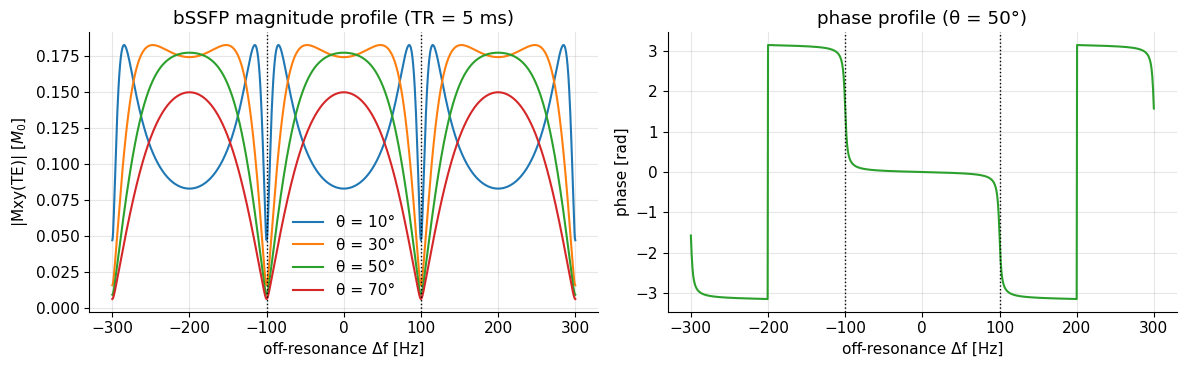

In [11]:
def bssfp_steady_state(theta, TR, T1, T2, df, TE=None, alternate=True):
    """Complex bSSFP signal Mxy(TE) in steady state, solved as a 3x3 linear system per Δf.

    theta [rad], TR/TE/T1/T2 [s], df [Hz] (scalar or array). Arrays T1, T2 broadcast with df.
    alternate=True: RF phase alternates 0/180° (standard), equivalent to beta += pi."""
    TE = TR / 2 if TE is None else TE
    df, T1, T2 = np.broadcast_arrays(np.asarray(df, float), np.asarray(T1, float), np.asarray(T2, float))
    shape = df.shape
    df, T1, T2 = df.ravel(), T1.ravel(), T2.ravel()
    beta = 2 * np.pi * df * TR + (np.pi if alternate else 0.0)

    def free_prec(tau, beta_tau):                         # batch of (A, b) for a free-precession interval tau
        E1, E2 = np.exp(-tau / T1), np.exp(-tau / T2)
        c, s = np.cos(-beta_tau), np.sin(-beta_tau)        # Rz(-beta): left-handed precession
        A = np.zeros((len(df), 3, 3))
        A[:, 0, 0], A[:, 0, 1], A[:, 1, 0], A[:, 1, 1] = E2 * c, -E2 * s, E2 * s, E2 * c
        A[:, 2, 2] = E1
        b = np.zeros((len(df), 3)); b[:, 2] = 1 - E1
        return A, b

    R = rf_rotation(theta)
    A, b = free_prec(TR, beta)
    lhs = np.eye(3)[None] - np.einsum("ij,njk->nik", R, A)
    Mp = np.linalg.solve(lhs, (b @ R.T)[..., None])[..., 0]     # M just after the pulse
    Ah, bh = free_prec(TE, beta * TE / TR)
    M_te = np.einsum("nij,nj->ni", Ah, Mp) + bh
    return (M_te[:, 0] + 1j * M_te[:, 1]).reshape(shape)

TR, theta = 5e-3, np.radians(50)
T1, T2 = 0.6, 0.08                               # white matter at 1.5 T [s]
s0 = bssfp_steady_state(theta, TR, T1, T2, 0.0)
print(f"on-resonance |S| = {abs(s0):.4f};  mt.bssfp_signal = {mt.bssfp_signal(theta, TR/2, TR, T1, T2):.4f}")
print(f"short-TR limit (M0/2) sqrt(T2/T1) = {0.5*np.sqrt(T2/T1):.4f} "
      f"(at theta_opt = {np.degrees(np.arccos((T1-T2)/(T1+T2))):.0f}°: {abs(bssfp_steady_state(np.arccos((T1-T2)/(T1+T2)), TR, T1, T2, 0.0)):.4f})")

df = np.linspace(-1.5 / TR, 1.5 / TR, 1201)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for th_deg in [10, 30, 50, 70]:
    s = bssfp_steady_state(np.radians(th_deg), TR, T1, T2, df)
    axes[0].plot(df, np.abs(s), label=f"θ = {th_deg}°")
s = bssfp_steady_state(theta, TR, T1, T2, df)
axes[1].plot(df, np.angle(s), color="C2")
for ax in axes:
    for k in (-1, 1):
        ax.axvline(k / (2 * TR), color="k", ls=":", lw=1)
    ax.set_xlabel("off-resonance Δf [Hz]")
axes[0].set_ylabel("|Mxy(TE)| [$M_0$]"); axes[0].legend(); axes[0].set_title(f"bSSFP magnitude profile (TR = {TR*1e3:.0f} ms)")
axes[1].set_ylabel("phase [rad]"); axes[1].set_title("phase profile (θ = 50°)")
plt.tight_layout(); plt.show()

The steady-state solver reproduces `mt.bssfp_signal` exactly on resonance. The profile is periodic in $\Delta f$ with period $1/TR$ (200 Hz here). Near $\Delta f = \pm 1/(2TR)$ (dotted lines) the signal collapses: these are the **dark bands**. The phase jumps by π across each band, a property used in some fat–water separation methods.

In an image, $\Delta f$ varies smoothly with position (imperfect shim, susceptibility), so the bands appear as dark stripes along iso-frequency contours:

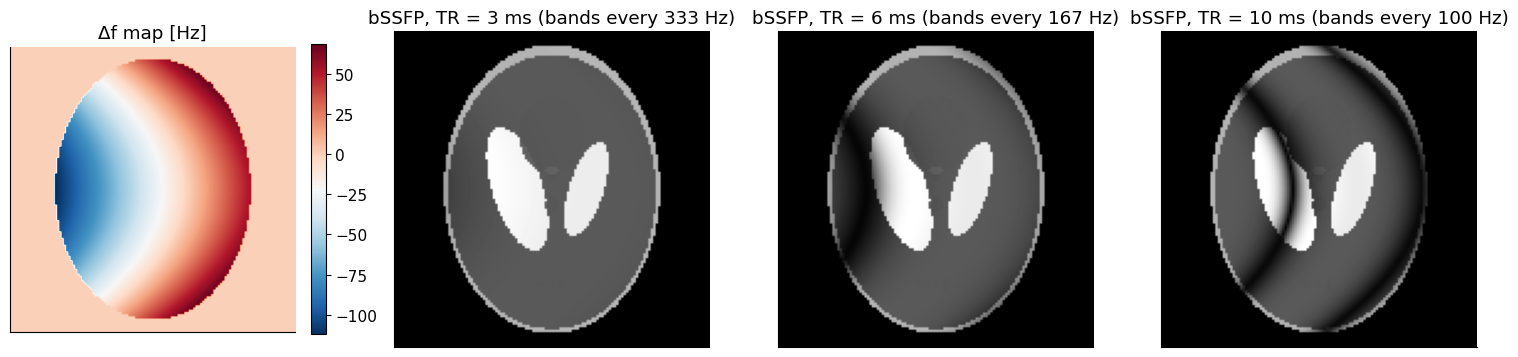

In [12]:
N = 128
ph = mt.tissue_phantom(N)
yy, xx = np.mgrid[1:-1:N * 1j, -1:1:N * 1j]
df_map = 120 * xx + 90 * yy ** 2 - 30                 # smooth field error [Hz] (poor shim)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
im = axes[0].imshow(df_map * (ph["labels"] > 0), cmap="RdBu_r"); axes[0].set_title("Δf map [Hz]")
axes[0].set_xticks([]); axes[0].set_yticks([]); plt.colorbar(im, ax=axes[0], fraction=0.046)
for ax, TR_ in zip(axes[1:], [3e-3, 6e-3, 10e-3]):
    s = bssfp_steady_state(np.radians(50), TR_, ph["T1"], ph["T2"], df_map)
    mt.show_image(ph["M0"] * np.abs(s), ax=ax, title=f"bSSFP, TR = {TR_*1e3:.0f} ms (bands every {1/TR_:.0f} Hz)")
plt.tight_layout(); plt.show()

Short TR pushes the bands apart (period $1/TR$ in Hz); with TR = 3 ms the whole field error (about −110 … +70 Hz) fits between two bands (at ±167 Hz). This is why bSSFP is always run with the shortest possible TR, and why it is harder at 3 T than at 1.5 T (field errors in Hz double). Note also the contrast: fluid (CSF) is very bright, the T2/T1 signature.

> **🔧 Engineering reality:** Keeping TR at 3–4 ms needs strong, fast gradients; on top, the many RF pulses per second push SAR. At 3 T bSSFP (e.g. cardiac cine) is often SAR-limited, forcing lower flip angles. Good **shimming** (adjusting $\Delta B_0$ with shim coils, see [Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb)) over the region of interest is essential.

### 3.5 Contrast of the gradient-echo family side by side

The same isochromat simulator gives SSFP-FID (signal just after the pulse) and SSFP-echo (signal just before the next pulse) for a sequence with an unbalanced gradient and no RF spoiling. Let's compute all four types for the tissues of the phantom ($TR$ = 10 ms for the unbalanced sequences, 5 ms for bSSFP, θ = 30°, TE ≈ 0, $T_2^*=T_2$; 1.5 T values):

sequence                    fat       WM       GM      CSF   lesion
spoiled GRE (FLASH)       0.118    0.057    0.037    0.011    0.027
SSFP-FID (FISP)           0.183    0.128    0.110    0.175    0.111
SSFP-echo (PSIF)          0.121    0.092    0.085    0.171    0.093
bSSFP (TrueFISP)          0.217    0.174    0.159    0.234    0.165


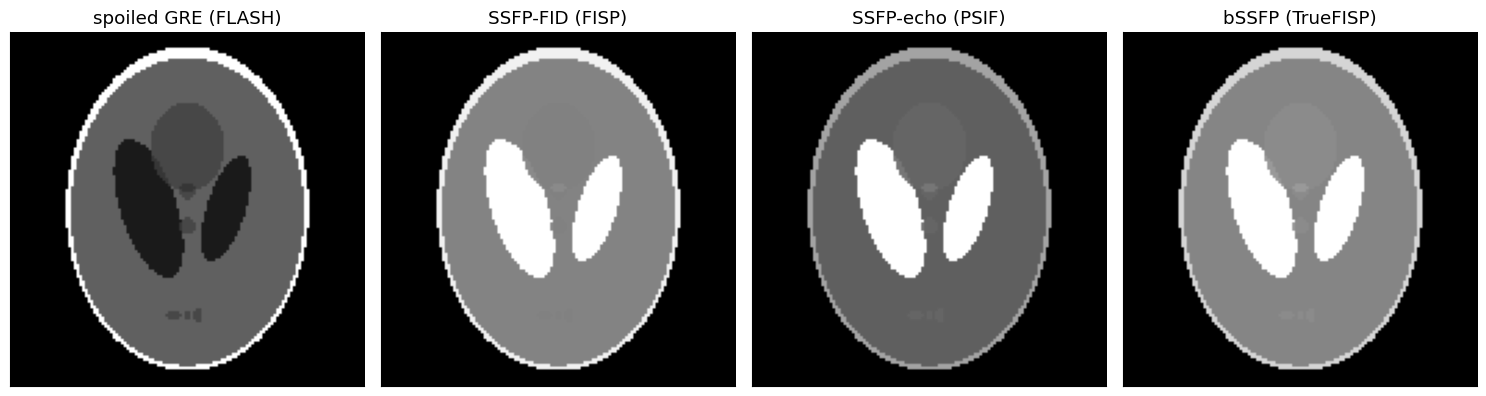

In [13]:
ph = mt.tissue_phantom(128)
tissues = {1: "fat", 2: "WM", 3: "GM", 4: "CSF", 5: "lesion"}
TR, th = 10e-3, np.radians(30)
results = {"spoiled GRE (FLASH)": {}, "SSFP-FID (FISP)": {}, "SSFP-echo (PSIF)": {}, "bSSFP (TrueFISP)": {}}
for lab in tissues:
    T1 = ph["T1"][ph["labels"] == lab][0]; T2 = ph["T2"][ph["labels"] == lab][0]
    n_tr = int(min(6 * T1 / TR, 2500))                           # run to (near) steady state
    results["spoiled GRE (FLASH)"][lab] = gre_isochromat_sim(th, TR, T1, T2, n_tr=n_tr, rf_spoil=True)[0][0]
    sp, sm = gre_isochromat_sim(th, TR, T1, T2, n_tr=n_tr)
    results["SSFP-FID (FISP)"][lab], results["SSFP-echo (PSIF)"][lab] = sp[0], sm[0]
    results["bSSFP (TrueFISP)"][lab] = abs(bssfp_steady_state(th, 5e-3, T1, T2, 0.0))

print(f"{'sequence':22s}" + "".join(f"{tissues[l]:>9s}" for l in tissues))
for name, r in results.items():
    print(f"{name:22s}" + "".join(f"{r[l]:9.3f}" for l in tissues))

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (name, r) in zip(axes, results.items()):
    img = np.zeros((128, 128))
    for lab, v in r.items():
        img[ph["labels"] == lab] = ph["M0"][ph["labels"] == lab][0] * v
    mt.show_image(img, ax=ax, title=name)
plt.tight_layout(); plt.show()

Read across the table: spoiled GRE is T1-weighted (fat brightest, CSF dark); SSFP-FID lifts CSF somewhat (T2 contribution); SSFP-echo is dominated by long-T2 CSF (strongly T2-weighted, but low signal overall); bSSFP gives by far the highest signals, with fluid and fat bright (both have high T2/T1).

## 4. Magnetization-prepared fast gradient-echo sequences

Magnetization preparation schemes such as inversion recovery, T2 preparation and magnetization transfer encode contrast in the **longitudinal** magnetization. That contrast can then be imaged efficiently with multiple fast gradient-echo readouts after a single preparation module.

The most common sequence of this type is the **Magnetization-Prepared Rapid Gradient Echo (MPRAGE)** for brain imaging. It uses an inversion-recovery preparation to create T1-weighted contrast, followed by a train of spoiled gradient-echo readouts with small flip angles (which add little contrast of their own).

![Magnetization-prepared fast gradient-echo pulse sequence: a preparation module, then a train of small-flip readouts θ with TR/TE, then a recovery time.](../images/pulse_sequence-diagram-mprage.png)

This sequence has additional parameters: the recovery time $T_{recovery}$ (called $T_D$ below) after the readouts, the number of readouts per preparation $N_{segments}$, and the parameters of the preparation itself (for inversion: $TI$). On scanners, "TR" of an MPRAGE usually means the time between inversions ($TR_{prep}$), and $TI$ the time from the inversion to the readout of the k-space centre.

First, the original book's simulation, ported to SI units. It starts from full magnetization, inverts, waits, then runs the readouts. *(Corrections: the original's variable `T_recovery` is actually used as the delay between inversion and the first readout, i.e. it plays the role of an inversion time, not of the recovery time in the diagram; and the original's T2 values had gray and white matter swapped, WM 110 ms > GM 80 ms. At 3 T, GM T2 ≈ 100 ms > WM T2 ≈ 75 ms.)*

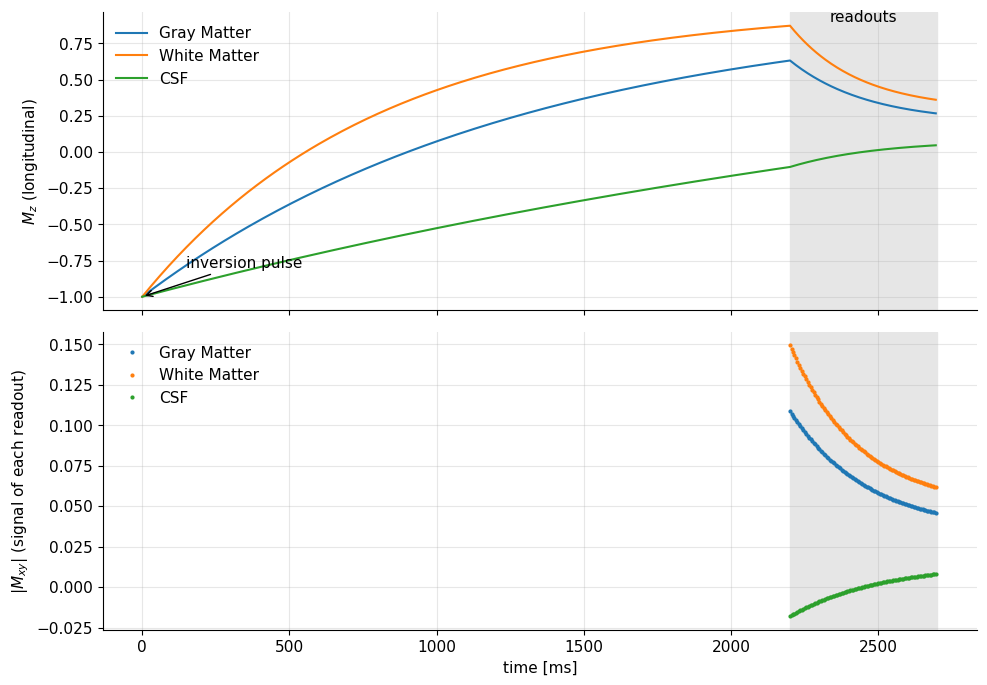

In [14]:
# Port of the original MPRAGE simulation (single inversion from equilibrium), SI units
flip_angle = np.radians(10)        # readout flip angle [rad]
TE = 1e-3                          # echo time [s]
TR = 5e-3                          # readout repetition time [s]
N_segments = 100                   # readouts per inversion
T_inv_to_readout = 2.2             # delay after inversion pulse [s] (original name: T_recovery)

MZ_start = 1.0                     # initial longitudinal magnetization (equilibrium)
MZ_inversion = -MZ_start           # right after the inversion pulse

t_recovery = np.arange(0, T_inv_to_readout, 10e-3)               # time axis of the delay [s]
t_segments = np.arange(N_segments) * TR + T_inv_to_readout       # times of the readouts [s]

tissues3T = {  # approximate 3 T values [s]
    "Gray Matter": {"T1": 1.30, "T2": 0.100},
    "White Matter": {"T1": 0.80, "T2": 0.075},
    "CSF": {"T1": 3.70, "T2": 1.70},
}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for name, p in tissues3T.items():
    T1, T2 = p["T1"], p["T2"]
    MZ_recovery = MZ_inversion * np.exp(-t_recovery / T1) + (1 - np.exp(-t_recovery / T1))   # inversion recovery
    MZ_seg = np.zeros(N_segments); MXY_seg = np.zeros(N_segments)
    MZ_seg[0] = MZ_inversion * np.exp(-T_inv_to_readout / T1) + (1 - np.exp(-T_inv_to_readout / T1))
    for n in range(1, N_segments):   # each readout pulse leaves cos(theta) of Mz, then T1 recovery for TR
        MZ_seg[n] = MZ_seg[n - 1] * np.cos(flip_angle) * np.exp(-TR / T1) + (1 - np.exp(-TR / T1))
    MXY_seg = MZ_seg * np.sin(flip_angle) * np.exp(-TE / T2)        # signal of each readout
    ax1.plot(np.concatenate((t_recovery, t_segments)) * 1e3, np.concatenate((MZ_recovery, MZ_seg)), label=name)
    ax2.plot(t_segments * 1e3, MXY_seg, "o", ms=2, label=name)
for ax in (ax1, ax2):
    ax.axvspan(T_inv_to_readout * 1e3, (T_inv_to_readout + N_segments * TR) * 1e3, color="0.9", zorder=0)
    ax.legend()
ax1.annotate("inversion pulse", xy=(0, -1), xytext=(150, -0.8), arrowprops=dict(arrowstyle="->"))
ax1.text((T_inv_to_readout + N_segments * TR / 2) * 1e3, 0.9, "readouts", ha="center")
ax1.set_ylabel("$M_z$ (longitudinal)"); ax2.set_ylabel("$|M_{xy}|$ (signal of each readout)")
ax2.set_xlabel("time [ms]"); plt.tight_layout(); plt.show()

After 2.2 s, GM and WM have almost fully recovered (little T1 contrast), while CSF is still near zero. To get good GM/WM contrast you need a shorter inversion time, and in reality the sequence repeats every $TR_{prep}$, so the inversion never starts from full $M_0$. Let's extend the simulation to the **repeated steady state**: inversion → $(TI - \tfrac{N_{seg}}{2}TR)$ delay → $N_{seg}$ readouts (centre of k-space in the middle for linear ordering) → delay $T_D$ → next inversion.

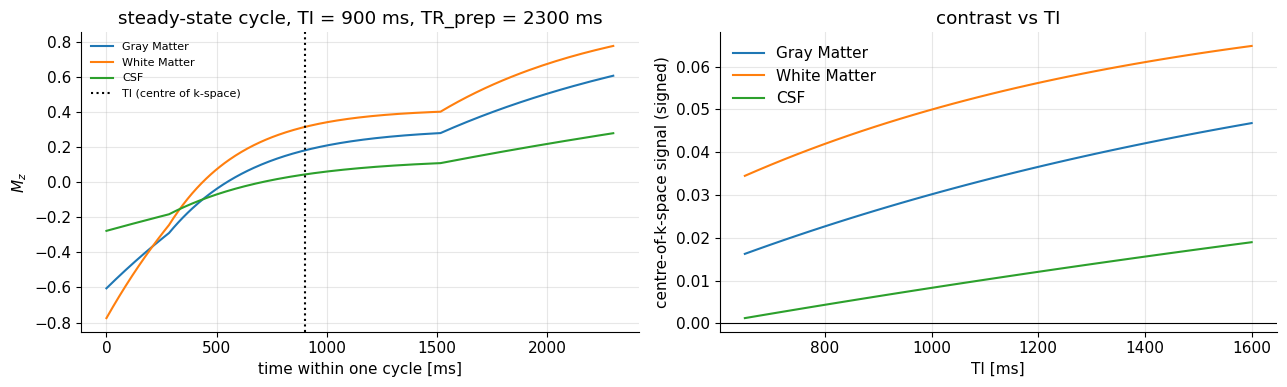

TI = 900 ms: WM 0.0462, GM 0.0266, CSF 0.0064 -> WM/GM ratio 1.74


In [15]:
def mprage_center_signal(TI, T1, T2s=0.05, TR_prep=2.3, N_seg=176, TR=7e-3, TE=3e-3, theta=np.radians(9), n_cycles=8):
    """Signal of the k-space-centre readout of an MPRAGE in steady state (linear ordering).

    TI: inversion -> centre readout [s]; TR_prep: inversion-to-inversion time [s]; N_seg readouts spaced TR.
    Returns (signal, t, Mz) with the Mz time course of the last cycle for plotting."""
    t_first = TI - (N_seg // 2) * TR                     # inversion -> first readout
    T_D = TR_prep - t_first - N_seg * TR                 # recovery after the readouts
    assert t_first > 0 and T_D > 0, "timing impossible"
    rec = lambda Mz, tau: 1 + (Mz - 1) * np.exp(-tau / T1)
    Mz = 1.0
    for _ in range(n_cycles):
        ts, Ms = [0.0], [-Mz]
        Mz = -Mz                                         # inversion (ideal, 180°)
        tau = np.linspace(0, t_first, 40)[1:]            # fine time grid for plotting the recovery
        ts += list(tau); Ms += list(rec(Mz, tau)); Mz = rec(Mz, t_first)
        sig = []
        for n in range(N_seg):
            sig.append(Mz * np.sin(theta) * np.exp(-TE / T2s))
            Mz = rec(Mz * np.cos(theta), TR); ts.append(t_first + (n + 1) * TR); Ms.append(Mz)
        tau = np.linspace(0, T_D, 40)[1:]
        ts += list(TR_prep - T_D + tau); Ms += list(rec(Mz, tau)); Mz = rec(Mz, T_D)
    return sig[N_seg // 2], np.array(ts), np.array(Ms)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
TIs = np.linspace(0.65, 1.6, 40)
for name, p in tissues3T.items():
    s, t_, Mz_ = mprage_center_signal(0.9, p["T1"])
    axes[0].plot(t_ * 1e3, Mz_, label=name)
    axes[1].plot(TIs * 1e3, [mprage_center_signal(ti, p["T1"])[0] for ti in TIs], label=name)
axes[0].axvline(900, color="k", ls=":", label="TI (centre of k-space)")
axes[0].set_xlabel("time within one cycle [ms]"); axes[0].set_ylabel("$M_z$"); axes[0].set_title("steady-state cycle, TI = 900 ms, TR_prep = 2300 ms")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("TI [ms]"); axes[1].set_ylabel("centre-of-k-space signal (signed)"); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("contrast vs TI"); axes[1].legend()
plt.tight_layout(); plt.show()
s_wm = mprage_center_signal(0.9, 0.8)[0]; s_gm = mprage_center_signal(0.9, 1.3)[0]; s_csf = mprage_center_signal(0.9, 3.7)[0]
print(f"TI = 900 ms: WM {s_wm:.4f}, GM {s_gm:.4f}, CSF {s_csf:.4f} -> WM/GM ratio {s_wm/s_gm:.2f}")

With typical 3 T settings ($TR_{prep}$ = 2.3 s, TI = 900 ms, 176 readouts) the steady state gives WM brighter than GM and CSF close to its null (dark): the classic MPRAGE T1 contrast used for brain morphometry. Note that the magnetization keeps changing *during* the readout train, so each k-space line has a slightly different weighting. That is another k-space modulation (as in FSE) and causes some blurring and edge effects.

> **🔧 Engineering reality:** MPRAGE is run in 3D (≈1 mm isotropic, ~5 min) because the gradient-echo readouts are so short ([Volumetric Imaging](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb)). Real inversion pulses are adiabatic (insensitive to $B_1^+$ errors, see [Fun with RF Pulses](../pass2_deep_dive/J3_Fun_with_RF_Pulses.ipynb)). The remaining $B_1^+$ inhomogeneity at 7 T affects the readout flip angles; MP2RAGE (two readouts at different TIs, combined) cancels much of it.

## 5. Vendor acronym translation table

Each vendor uses its own names for the same physics. The table lists common equivalents (names change between software versions; check vendor documentation and the [Glossary and Acronyms](../reference/Glossary_and_Acronyms.ipynb)).

| Generic sequence | Siemens | GE | Philips | Canon (Toshiba) |
|---|---|---|---|---|
| Fast/turbo spin echo | TSE | FSE | TSE | FSE |
| Single-shot FSE + half Fourier | HASTE | SSFSE | SSh-TSE (UltraFast SE) | FASE |
| 3D FSE, variable flip angle | SPACE | CUBE | VISTA | 3D MVOX |
| Inversion-recovery FSE (FLAIR, STIR) | TIRM / TSE-IR | FSE-IR | IR-TSE | FastFLAIR / FastSTIR |
| Spoiled GRE | FLASH | SPGR | T1-FFE | RF-spoiled FE |
| Fast spoiled GRE / prepared | TurboFLASH | FSPGR | TFE | Fast FE |
| 3D IR-prepared T1 (MPRAGE) | MPRAGE | BRAVO (3D IR-FSPGR) | 3D TFE (IR) | 3D MPRAGE |
| SSFP-FID (unspoiled) | FISP | GRASS / MPGR | FFE | SSFP |
| SSFP-echo | PSIF | SSFP | T2-FFE | — |
| Balanced SSFP | TrueFISP | FIESTA | Balanced FFE (bFFE) | TrueSSFP |
| Multi-echo GRE | MEDIC | MERGE | M-FFE | — |
| 3D fat-sat T1 GRE (body) | VIBE | LAVA | THRIVE | QUICK 3D |
| EPI | EPI | EPI | EPI (FFE-EPI, SE-EPI) | EPI |
| Parallel imaging | GRAPPA, mSENSE | ARC, ASSET | SENSE | SPEEDER |
| Simultaneous multislice | SMS | HyperBand | Multiband SENSE | MultiBand SPEEDER |

> **⚠️ Common confusion:** The same letters mean different things across vendors: "SSFP" at GE is the SSFP-*echo* sequence (Siemens PSIF), not balanced SSFP; Philips' "FFE" is any gradient echo ("fast field echo"), "T1-FFE" the spoiled one; and Philips' "TFE" is a gradient-echo sequence, not a spin-echo one.

## Try it yourself (interactive)

Explore the bSSFP off-resonance profile: change flip angle, TR, T1 and T2.

In [16]:
try:
    from ipywidgets import interact, FloatSlider
    def explore_bssfp(flip_deg=50.0, TR_ms=5.0, T1_ms=600.0, T2_ms=80.0):
        TR_ = TR_ms * 1e-3
        dfs = np.linspace(-1.5 / TR_, 1.5 / TR_, 600)
        s = bssfp_steady_state(np.radians(flip_deg), TR_, T1_ms * 1e-3, T2_ms * 1e-3, dfs)
        plt.figure(figsize=(7, 3)); plt.plot(dfs, np.abs(s)); plt.xlabel("Δf [Hz]"); plt.ylabel("|Mxy|")
        plt.title(f"bSSFP profile, period 1/TR = {1/TR_:.0f} Hz"); plt.show()
    interact(explore_bssfp, flip_deg=FloatSlider(min=5, max=90, step=5, value=50),
             TR_ms=FloatSlider(min=2, max=15, step=0.5, value=5),
             T1_ms=FloatSlider(min=200, max=4000, step=50, value=600),
             T2_ms=FloatSlider(min=20, max=2000, step=10, value=80))
except ImportError:
    print("ipywidgets not available")

interactive(children=(FloatSlider(value=50.0, description='flip_deg', max=90.0, min=5.0, step=5.0), FloatSlide…

## Key takeaways

* **FSE/TSE/RARE** acquires $ETL$ spin echoes per excitation: $T_{scan}=TR\cdot N_{PE}/ETL$. The **view ordering** decides $TE_{eff}$ (contrast); the echo-to-echo T2 decay is a k-space modulation that causes **T2 blurring** in long trains. SAR from refocusing pulses is the main limit.
* **EPI** acquires a whole image with a zig-zag trajectory of gradient echoes. Lines are $t_{esp}$ apart, so the PE bandwidth per pixel is only $1/(N_{PE}t_{esp})$ and off-resonance $\Delta f$ shifts pixels by $\Delta f\,N_{PE}\,t_{esp}$: geometric **distortion** and fat displacement (fat suppression is mandatory).
* Odd/even echo inconsistencies cause **N/2 ghosts** of relative amplitude ≈ $|\sin(\phi/2)|$; reference scans correct them.
* **Spoiling** (gradient + quadratic RF phase cycling) is needed to make a short-TR GRE behave like the ideal T1-weighted spoiled formula; gradient spoiling alone leaves coherent residual signal.
* The unspoiled family: SSFP-FID (FISP/GRASS), SSFP-echo (PSIF, T2w) and **bSSFP** (TrueFISP/FIESTA, T2/T1, highest SNR). bSSFP shows **dark bands** at $\Delta f=\pm1/(2TR)$, repeating every $1/TR$; keep TR short and shim well.
* **MPRAGE** prepares T1 contrast with an inversion and reads it out with many small-flip GRE readouts; TI and $TR_{prep}$ set the contrast in a repeated steady state.
* Vendors use different names for the same sequences; a translation table avoids confusion.

## Check your understanding

1. A T2-weighted FSE uses TR = 3 s, 320 phase-encode lines, ETL = 20, $t_{esp}$ = 9 ms, NEX = 1, linear ordering. What is the scan time and the approximate effective TE?

<details><summary>Answer</summary>

Shots = 320/20 = 16, so $T_{scan}$ = 3 s × 16 = 48 s. With linear ordering the centre block is acquired around echo 10–11: $TE_{eff}\approx 10.5\times 9$ ms ≈ 95 ms.

</details>

2. A single-shot EPI has 96 phase-encode lines with echo spacing 0.6 ms at 3 T. By how many pixels is fat displaced, and by how many pixels does a 60 Hz field error shift tissue? What changes with parallel imaging R = 2?

<details><summary>Answer</summary>

$BW_{pix,PE} = 1/(96\times0.6\,\text{ms}) = 17.4$ Hz/pixel. Fat (−3.5 ppm ≈ −447 Hz) shifts by ≈ 26 pixels; 60 Hz shifts ≈ 3.5 pixels. With R = 2 only 48 lines are acquired per train with the same $t_{esp}$, so $BW_{pix,PE}$ doubles and all shifts halve (13 and 1.7 pixels).

</details>

3. Your EPI image shows a faint copy of the head shifted by half the FOV in the phase-encode direction. What causes it, and how large must the odd/even phase error be for a ghost of 5 % of the image intensity?

<details><summary>Answer</summary>

An N/2 (Nyquist) ghost from inconsistencies between lines acquired with positive and negative readout gradients (eddy currents, timing delays). Ghost fraction ≈ $|\sin(\phi/2)| = 0.05 \Rightarrow \phi \approx 0.1$ rad ≈ 5.7°. Correction uses a reference scan (lines without blips) to estimate and remove the phase difference.

</details>

4. Why is a gradient spoiler alone not enough to make a short-TR gradient echo behave like the "spoiled" signal equation, and what does RF spoiling do?

<details><summary>Answer</summary>

A fixed spoiler only dephases the isochromats within a voxel; the transverse magnetization is not destroyed and, since the same dephasing repeats every TR, later RF pulses refocus parts of it into coherent echoes that add to the signal (a steady state with T2 dependence). RF spoiling changes the RF phase quadratically from TR to TR, so these pathways add with varying phases and cancel on average, leaving essentially only the freshly excited longitudinal magnetization: the ideal spoiled behaviour.

</details>

5. A bSSFP cine at 3 T with TR = 4 ms shows dark bands across the heart. What frequency offset causes a band, and what are your options?

<details><summary>Answer</summary>

Bands occur at $\Delta f = \pm 1/(2TR) = \pm125$ Hz (repeating every 250 Hz). Options: better shim over the heart (localized shim volume), shorter TR (stronger gradients, lower resolution, or partial echo), shift the RF centre frequency ("frequency scout") to move a band out of the region of interest, or acquire at lower field.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Fast Imaging Pulse Sequences".
Changes: added symbol table, scan-time numbers, FSE view-ordering/T2-blurring simulation, EPI gradient waveform → k-space trajectory, derivation of the EPI pixel shift $\Delta f N_{PE} t_{esp}$ with a distortion simulation, N/2-ghost derivation/simulation/correction, isochromat simulation of gradient vs RF spoiling, Bloch steady-state bSSFP profile and banding images, a GRE-family contrast comparison, an extended steady-state MPRAGE model, vendor acronym table. Corrected: Philips FSE name (TSE, not TFE), RF spoiling is not used in GRASS/FISP, PSIF is T2- (not T2/T1-) weighted, spoiled GRE is not "pure" T1, swapped GM/WM T2 values and the meaning of `T_recovery` in the original MPRAGE code; typos ("refouces", "full spoil").*